# Chat-with-your-PDF

- **Learn:** Retrieval-Augmented Generation: chunking documents, storing embeddings in a vector database, retrieving relevant chunks and feeding them to the model. Learn reranking too.

- **Ship:** Chat-with-your-PDF, with no framework. Build the pipeline yourself first. Use frameworks later, once you know what they’re hiding from you.

## Installing and Importing Necessary Libraries and Dependencies

In [1]:
# Install required libraries
!pip install -q langchain_community==0.3.27 \
              langchain==0.3.27 \
              chromadb==1.0.15 \
              pymupdf==1.26.3 \
              "tiktoken>=0.12.0" \
              datasets==4.0.0 \
              evaluate==0.4.5 \
              langchain_openai==0.3.30


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\jimbo\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


## Import OS Environments

In [2]:
import os
from dotenv import load_dotenv
load_dotenv()  # reads .env from this folder

# LM Studio Environment Variables
BASE_URL    = os.environ["LMSTUDIO_BASE_URL"]       # e.g. http://localhost:1234/v1
CHAT_MODEL  = os.environ["LMSTUDIO_CHAT_MODEL"]     # openai/gpt-oss-20b
EMBED_MODEL = os.environ["LMSTUDIO_EMBED_MODEL"]

from langchain_openai import ChatOpenAI, OpenAIEmbeddings

def get_llm():
    """Chat model served by LM Studio (OpenAI-compatible API)."""
    return ChatOpenAI(model=CHAT_MODEL, base_url=BASE_URL, api_key="lm-studio", temperature=0)

def get_embeddings():
    """Embedding model served by LM Studio."""
    return OpenAIEmbeddings(
        model=EMBED_MODEL,
        base_url=BASE_URL,
        api_key="lm-studio",
        check_embedding_ctx_length=False,  # LM Studio expects raw strings, not token arrays
    )


## Retriever
 
Let's index 3 blog posts.

In [3]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import WebBaseLoader
from langchain_community.vectorstores import Chroma

urls = [
    "https://lilianweng.github.io/posts/2023-06-23-agent/",
    "https://lilianweng.github.io/posts/2023-03-15-prompt-engineering/",
    "https://lilianweng.github.io/posts/2023-10-25-adv-attack-llm/",
]

docs = [WebBaseLoader(url).load() for url in urls]
docs_list = [item for sublist in docs for item in sublist]

text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=250, chunk_overlap=0
)
doc_splits = text_splitter.split_documents(docs_list)

# Add to vectorDB
vectorstore = Chroma.from_documents(
    documents=doc_splits,
    collection_name="rag-chroma",
    embedding=get_embeddings(),
)
retriever = vectorstore.as_retriever()

C:\Users\jimbo\AppData\Local\Temp\ipykernel_9932\1827201983.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


## LLMs

In [4]:
### Retrieval Grader


from langchain_core.prompts import ChatPromptTemplate
from pydantic import BaseModel, Field


# Data model
class GradeDocuments(BaseModel):
    """Binary score for relevance check on retrieved documents."""

    binary_score: str = Field(
        description="Documents are relevant to the question, 'yes' or 'no'"
    )


# LLM with function call
llm = get_llm()
structured_llm_grader = llm.with_structured_output(GradeDocuments)

# Prompt
system = """You are a grader assessing relevance of a retrieved document to a user question. \n 
    It does not need to be a stringent test. The goal is to filter out erroneous retrievals. \n
    If the document contains keyword(s) or semantic meaning related to the user question, grade it as relevant. \n
    Give a binary score 'yes' or 'no' score to indicate whether the document is relevant to the question."""
grade_prompt = ChatPromptTemplate.from_messages(
    [
        ("system", system),
        ("human", "Retrieved document: \n\n {document} \n\n User question: {question}"),
    ]
)

retrieval_grader = grade_prompt | structured_llm_grader
question = "agent memory"
docs = retriever.invoke(question)
doc_txt = docs[1].page_content
print(retrieval_grader.invoke({"question": question, "document": doc_txt}))

binary_score='yes'


In [5]:
### Generate

from langchain_core.output_parsers import StrOutputParser

# Prompt (inlined copy of the "rlm/rag-prompt" hub prompt, so no hub access is needed)
prompt = ChatPromptTemplate.from_messages(
    [
        (
            "human",
            "You are an assistant for question-answering tasks. Use the following pieces of retrieved context "
            "to answer the question. If you don't know the answer, just say that you don't know. "
            "Use three sentences maximum and keep the answer concise.\n"
            "Question: {question} \nContext: {context} \nAnswer:",
        )
    ]
)

# LLM
llm = get_llm()


# Post-processing
def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)


# Chain
rag_chain = prompt | llm | StrOutputParser()

# Run
generation = rag_chain.invoke({"context": format_docs(docs), "question": question})
print(generation)

Agent memory in LLM‑powered systems is split into **short‑term** (in‑context learning) and **long‑term** (external vector stores that can be queried for past events). A **retrieval model** surfaces relevant, recent or important memories to the prompt, while a **reflection mechanism** condenses those memories into higher‑level inferences that guide future planning. Together they allow an autonomous agent to remember experiences, reason over them, and act accordingly.


In [6]:
### Hallucination Grader


# Data model
class GradeHallucinations(BaseModel):
    """Binary score for hallucination present in generation answer."""

    binary_score: str = Field(
        description="Answer is grounded in the facts, 'yes' or 'no'"
    )


# LLM with function call
llm = get_llm()
structured_llm_grader = llm.with_structured_output(GradeHallucinations)

# Prompt
system = """You are a grader assessing whether an LLM generation is grounded in / supported by a set of retrieved facts. \n 
     Give a binary score 'yes' or 'no'. 'Yes' means that the answer is grounded in / supported by the set of facts."""
hallucination_prompt = ChatPromptTemplate.from_messages(
    [
        ("system", system),
        ("human", "Set of facts: \n\n {documents} \n\n LLM generation: {generation}"),
    ]
)

hallucination_grader = hallucination_prompt | structured_llm_grader
hallucination_grader.invoke({"documents": format_docs(docs), "generation": generation})

GradeHallucinations(binary_score='yes')

In [7]:
### Answer Grader


# Data model
class GradeAnswer(BaseModel):
    """Binary score to assess answer addresses question."""

    binary_score: str = Field(
        description="Answer addresses the question, 'yes' or 'no'"
    )


# LLM with function call
llm = get_llm()
structured_llm_grader = llm.with_structured_output(GradeAnswer)

# Prompt
system = """You are a grader assessing whether an answer addresses / resolves a question \n 
     Give a binary score 'yes' or 'no'. Yes' means that the answer resolves the question."""
answer_prompt = ChatPromptTemplate.from_messages(
    [
        ("system", system),
        ("human", "User question: \n\n {question} \n\n LLM generation: {generation}"),
    ]
)

answer_grader = answer_prompt | structured_llm_grader
answer_grader.invoke({"question": question, "generation": generation})

GradeAnswer(binary_score='yes')

In [8]:
### Question Re-writer

# LLM
llm = get_llm()

# Prompt
system = """You a question re-writer that converts an input question to a better version that is optimized \n 
     for vectorstore retrieval. Look at the input and try to reason about the underlying semantic intent / meaning."""
re_write_prompt = ChatPromptTemplate.from_messages(
    [
        ("system", system),
        (
            "human",
            "Here is the initial question: \n\n {question} \n Formulate an improved question.",
        ),
    ]
)

question_rewriter = re_write_prompt | llm | StrOutputParser()
question_rewriter.invoke({"question": question})

'**Revised Question**\n\n*What mechanisms do autonomous agents use to store, retrieve, and maintain memory over time, and how can these approaches be implemented in a vector‑store based system?*'

# Graph 

Capture the flow in as a graph.

## Graph state

In [ ]:
from typing import List

from typing_extensions import TypedDict

MAX_RETRIES = 2  # max number of generation attempts before giving up


class GraphState(TypedDict):
    """
    Represents the state of our graph.

    Attributes:
        question: question
        generation: LLM generation
        documents: list of documents
        retries: number of generation attempts so far
    """

    question: str
    generation: str
    documents: List[str]
    retries: int

In [10]:
### Nodes


def retrieve(state):
    """
    Retrieve documents

    Args:
        state (dict): The current graph state

    Returns:
        state (dict): New key added to state, documents, that contains retrieved documents
    """
    print("---RETRIEVE---")
    question = state["question"]

    # Retrieval
    documents = retriever.invoke(question)
    return {"documents": documents, "question": question}


def generate(state):
    """
    Generate answer

    Args:
        state (dict): The current graph state

    Returns:
        state (dict): New key added to state, generation, that contains LLM generation
    """
    print("---GENERATE---")
    question = state["question"]
    documents = state["documents"]
    retries = state.get("retries", 0) + 1  # count this attempt

    # RAG generation
    generation = rag_chain.invoke({"context": format_docs(documents), "question": question})
    return {
        "documents": documents,
        "question": question,
        "generation": generation,
        "retries": retries,
    }


def grade_documents(state):
    """
    Determines whether the retrieved documents are relevant to the question.

    Args:
        state (dict): The current graph state

    Returns:
        state (dict): Updates documents key with only filtered relevant documents
    """

    print("---CHECK DOCUMENT RELEVANCE TO QUESTION---")
    question = state["question"]
    documents = state["documents"]

    # Score each doc
    filtered_docs = []
    for d in documents:
        score = retrieval_grader.invoke(
            {"question": question, "document": d.page_content}
        )
        grade = score.binary_score
        if grade == "yes":
            print("---GRADE: DOCUMENT RELEVANT---")
            filtered_docs.append(d)
        else:
            print("---GRADE: DOCUMENT NOT RELEVANT---")
            continue
    return {"documents": filtered_docs, "question": question}


def transform_query(state):
    """
    Transform the query to produce a better question.

    Args:
        state (dict): The current graph state

    Returns:
        state (dict): Updates question key with a re-phrased question
    """

    print("---TRANSFORM QUERY---")
    question = state["question"]
    documents = state["documents"]

    # Re-write question
    better_question = question_rewriter.invoke({"question": question})
    return {"documents": documents, "question": better_question}


### Edges


def decide_to_generate(state):
    """
    Determines whether to generate an answer, or re-generate a question.

    Args:
        state (dict): The current graph state

    Returns:
        str: Binary decision for next node to call
    """

    print("---ASSESS GRADED DOCUMENTS---")
    state["question"]
    filtered_documents = state["documents"]

    if not filtered_documents:
        # All documents have been filtered check_relevance
        # We will re-generate a new query
        print(
            "---DECISION: ALL DOCUMENTS ARE NOT RELEVANT TO QUESTION, TRANSFORM QUERY---"
        )
        return "transform_query"
    else:
        # We have relevant documents, so generate answer
        print("---DECISION: GENERATE---")
        return "generate"


def grade_generation_v_documents_and_question(state):
    """
    Determines whether the generation is grounded in the document and answers question.

    Args:
        state (dict): The current graph state

    Returns:
        str: Decision for next node to call
    """

    print("---CHECK HALLUCINATIONS---")
    question = state["question"]
    documents = state["documents"]
    generation = state["generation"]
    retries = state.get("retries", 0)

    score = hallucination_grader.invoke(
        {"documents": format_docs(documents), "generation": generation}
    )
    grade = score.binary_score

    # Check hallucination
    if grade == "yes":
        print("---DECISION: GENERATION IS GROUNDED IN DOCUMENTS---")
        # Check question-answering
        print("---GRADE GENERATION vs QUESTION---")
        score = answer_grader.invoke({"question": question, "generation": generation})
        grade = score.binary_score
        if grade == "yes":
            print("---DECISION: GENERATION ADDRESSES QUESTION---")
            return "useful"
        else:
            print("---DECISION: GENERATION DOES NOT ADDRESS QUESTION---")
            if retries >= MAX_RETRIES:
                print(f"---MAX RETRIES ({MAX_RETRIES}) REACHED, GIVING UP---")
                return "give up"
            return "not useful"
    else:
        print("---DECISION: GENERATION IS NOT GROUNDED IN DOCUMENTS, RE-TRY---")
        if retries >= MAX_RETRIES:
            print(f"---MAX RETRIES ({MAX_RETRIES}) REACHED, GIVING UP---")
            return "give up"
        return "not supported"

## Build Graph

The just follows the flow we outlined in the figure above.

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	retrieve(retrieve)
	grade_documents(grade_documents)
	generate(generate)
	transform_query(transform_query)
	__end__([<p>__end__</p>]):::last
	__start__ --> retrieve;
	generate -. &nbsp;give up&nbsp; .-> __end__;
	generate -. &nbsp;not useful&nbsp; .-> transform_query;
	grade_documents -.-> generate;
	grade_documents -.-> transform_query;
	retrieve --> grade_documents;
	transform_query --> retrieve;
	generate -. &nbsp;not supported&nbsp; .-> generate;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



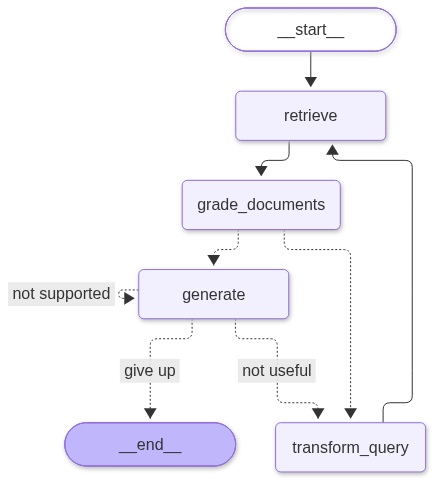

In [11]:
from langgraph.graph import END, StateGraph, START

workflow = StateGraph(GraphState)

# Define the nodes
workflow.add_node("retrieve", retrieve)  # retrieve
workflow.add_node("grade_documents", grade_documents)  # grade documents
workflow.add_node("generate", generate)  # generate
workflow.add_node("transform_query", transform_query)  # transform_query

# Build graph
workflow.add_edge(START, "retrieve")
workflow.add_edge("retrieve", "grade_documents")
workflow.add_conditional_edges(
    "grade_documents",
    decide_to_generate,
    {
        "transform_query": "transform_query",
        "generate": "generate",
    },
)
workflow.add_edge("transform_query", "retrieve")
workflow.add_conditional_edges(
    "generate",
    grade_generation_v_documents_and_question,
    {
        "not supported": "generate",
        "useful": END,
        "not useful": "transform_query",
        "give up": END,  # retry limit reached: return the last generation
    },
)

# Compile
app = workflow.compile()

# Draw the graph as a Mermaid state diagram
from IPython.display import Image, display

graph = app.get_graph()

# 1) Mermaid source text: paste into https://mermaid.live or a ```mermaid block in Markdown
print(graph.draw_mermaid())

# 2) Rendered image (uses the mermaid.ink web service, so it needs internet access)
try:
    display(Image(graph.draw_mermaid_png()))
except Exception as e:
    print(f"Could not render PNG ({type(e).__name__}); use the Mermaid text above instead.")

## Helper function

In [14]:
# To show the final result in a notebook, we can use the following helper function:

from IPython.display import Markdown, display

def show_result(state, snippet_len=200):
    """Render a final graph state (question, answer, retries, sources) as Markdown."""
    documents = state.get("documents", [])
    docs_md = "\n".join(
        f"{i}. `{d.metadata.get('source', 'unknown')}`\n\n   > {d.page_content[:snippet_len].strip()}…"
        for i, d in enumerate(documents, 1)
    )

    display(Markdown(f"""
### Question
{state.get("question", "")}

### Answer
{state.get("generation", "")}

### Retries
{state.get("retries", 0)}

### Source documents ({len(documents)})
{docs_md}
"""))


## Test Cases
### Test Case 1

In [15]:
# Inputs
inputs = {"question": "Explain how the different types of agent memory work?"}

In [ ]:
# Call the graph with the input question
final = app.invoke(inputs)

---RETRIEVE---
---CHECK DOCUMENT RELEVANCE TO QUESTION---
---GRADE: DOCUMENT NOT RELEVANT---
---GRADE: DOCUMENT RELEVANT---
---GRADE: DOCUMENT RELEVANT---
---GRADE: DOCUMENT RELEVANT---
---ASSESS GRADED DOCUMENTS---
---DECISION: GENERATE---
---GENERATE---
---CHECK HALLUCINATIONS---
---DECISION: GENERATION IS NOT GROUNDED IN DOCUMENTS, RE-TRY---
---GENERATE---
---CHECK HALLUCINATIONS---
---DECISION: GENERATION IS NOT GROUNDED IN DOCUMENTS, RE-TRY---
---GENERATE---
---CHECK HALLUCINATIONS---
---DECISION: GENERATION IS NOT GROUNDED IN DOCUMENTS, RE-TRY---
---MAX RETRIES (3) REACHED, GIVING UP---


In [17]:
# To show the final output in Markdown format
show_result(final)


### Question
Explain how the different types of agent memory work?

### Answer
Short‑term memory (STM) in an agent is the in‑context buffer that holds recent dialogue or facts for immediate reasoning—typically only a few dozen tokens and lasts seconds to minutes. Long‑term memory (LTM) is an external store, such as a vector database, that persists knowledge indefinitely; it can be queried on demand to retrieve past experiences, facts, or procedural steps. Tool use augments LTM by letting the agent call APIs or run code to fetch up‑to‑date data or perform actions that the base model cannot compute internally.

### Retries
3

### Source documents (3)
1. `https://lilianweng.github.io/posts/2023-06-23-agent/`

   > Short-term memory: I would consider all the in-context learning (See Prompt Engineering) as utilizing short-term memory of the model to learn.
Long-term memory: This provides the agent with the capabi…
2. `https://lilianweng.github.io/posts/2023-06-23-agent/`

   > Short-Term Memory (STM) or Working Memory: It stores information that we are currently aware of and needed to carry out complex cognitive tasks such as learning and reasoning. Short-term memory is bel…
3. `https://lilianweng.github.io/posts/2023-06-23-agent/`

   > They also discussed the risks, especially with illicit drugs and bioweapons. They developed a test set containing a list of known chemical weapon agents and asked the agent to synthesize them. 4 out o…


### Test Case 2

In [18]:
# Test Case 2
inputs = {"question": "Explain how chain of thought prompting works?"}
final = app.invoke(inputs)
show_result(final)

---RETRIEVE---
---CHECK DOCUMENT RELEVANCE TO QUESTION---
---GRADE: DOCUMENT RELEVANT---
---GRADE: DOCUMENT RELEVANT---
---GRADE: DOCUMENT NOT RELEVANT---
---GRADE: DOCUMENT NOT RELEVANT---
---ASSESS GRADED DOCUMENTS---
---DECISION: GENERATE---
---GENERATE---
---CHECK HALLUCINATIONS---
---DECISION: GENERATION IS GROUNDED IN DOCUMENTS---
---GRADE GENERATION vs QUESTION---
---DECISION: GENERATION ADDRESSES QUESTION---



### Question
Explain how chain of thought prompting works?

### Answer
Chain‑of‑Thought prompting asks a language model to “think step by step,” forcing it to break a complex problem into smaller, sequential sub‑tasks and generate intermediate reasoning before giving the final answer. This extra test‑time computation improves accuracy because each step can be checked or corrected, revealing the model’s internal logic. Extensions like Tree of Thoughts explore multiple possible steps at once, creating a search tree that can be traversed with BFS/DFS to find better solutions.

### Retries
1

### Source documents (2)
1. `https://lilianweng.github.io/posts/2023-06-23-agent/`

   > Component One: Planning#
A complicated task usually involves many steps. An agent needs to know what they are and plan ahead.
Task Decomposition#
Chain of thought (CoT; Wei et al. 2022) has become a s…
2. `https://lilianweng.github.io/posts/2023-03-15-prompt-engineering/`

   > [8] Wang et al. “Self-Consistency Improves Chain of Thought Reasoning in Language Models.” ICLR 2023.
[9] Diao et al. “Active Prompting with Chain-of-Thought for Large Language Models.” arXiv preprint…


## Reference
- https://github.com/langchain-ai/langgraph/tree/main/examples/rag/langgraph_self_rag.ipynb